## Model 1: Random Forest Classifier

### 1. Model Selection Rationale
* **Dataset Characteristics**: The dataset contains a mix of numerical and categorical features related to student demographics, academic background, and social-economic factors. Random Forest handles heterogeneous data exceptionally well without requiring extensive feature scaling.
* **Problem Type**: This is a multi-class/binary classification problem aimed at predicting student outcomes (Dropout, Enrolled, Graduate). Random Forest natively supports multi-class classification and handles complex non-linear relationships.
* **Strengths**:
  * High accuracy and robustness against overfitting through ensemble learning (bagging).
  * Built-in feature importance evaluation, which helps leadership identify key factors influencing student success.
  * Less sensitive to outliers and missing values compared to other algorithms.

Baseline Accuracy: 0.7243
Baseline Macro F1: 0.6627

Best Parameters: {'max_depth': 20, 'min_samples_split': 10, 'n_estimators': 100}
Best Mean CV Macro F1: 0.6991

Tuned Test Accuracy: 0.7254
Tuned Test Macro F1: 0.6778

Classification Report:
              precision    recall  f1-score   support

     Dropout     0.7743    0.7007    0.7357       284
    Enrolled     0.4175    0.5409    0.4712       159
    Graduate     0.8460    0.8077    0.8264       442

    accuracy                         0.7254       885
   macro avg     0.6793    0.6831    0.6778       885
weighted avg     0.7460    0.7254    0.7335       885



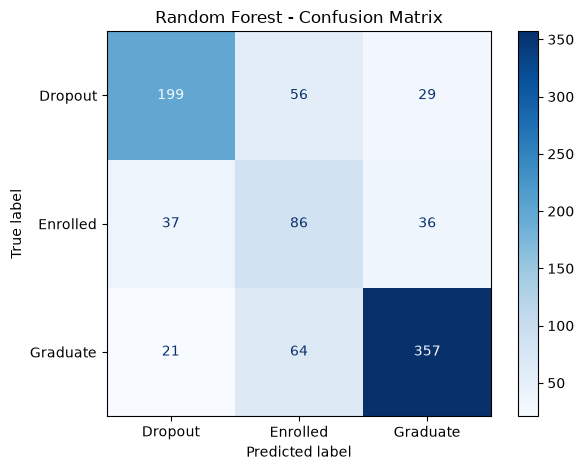

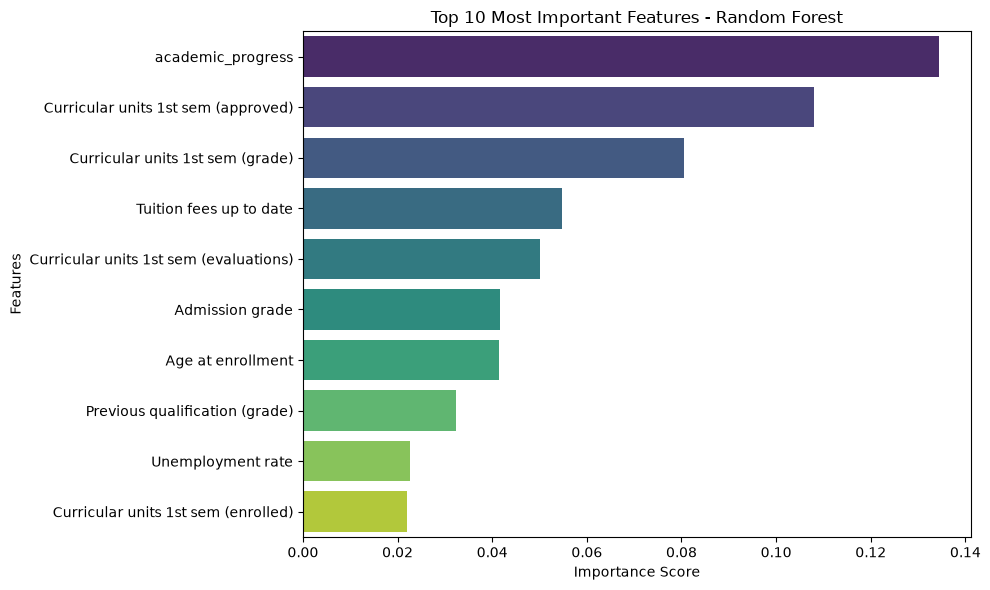

                               Feature  Importance
                     academic_progress    0.134506
   Curricular units 1st sem (approved)    0.108058
      Curricular units 1st sem (grade)    0.080454
               Tuition fees up to date    0.054725
Curricular units 1st sem (evaluations)    0.050017
                       Admission grade    0.041679
                     Age at enrollment    0.041522
        Previous qualification (grade)    0.032434
                     Unemployment rate    0.022668
   Curricular units 1st sem (enrolled)    0.022031


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load the preprocessed dataset (same path style as Model 2)
df = pd.read_csv("Dataset/preprocessed_data.csv")

# 2. Use the shared train/test split
train_data = df[df["split"] == "train"]
test_data = df[df["split"] == "test"]

X_train = train_data.drop(columns=["Target", "split"])
y_train = train_data["Target"]
X_test = test_data.drop(columns=["Target", "split"])
y_test = test_data["Target"]

labels = [0, 1, 2]
names = ["Dropout", "Enrolled", "Graduate"]

# 3. Baseline Random Forest (class_weight handles the imbalance)
rf_base = RandomForestClassifier(class_weight="balanced", random_state=42)
rf_base.fit(X_train, y_train)
y_pred_base = rf_base.predict(X_test)

print("Baseline Accuracy:", round(accuracy_score(y_test, y_pred_base), 4))
print("Baseline Macro F1:", round(f1_score(y_test, y_pred_base, average="macro"), 4))

# 4. Hyperparameter tuning (same 5-fold stratified CV as Model 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    refit=True
)
grid_search.fit(X_train, y_train)

print("\nBest Parameters:", grid_search.best_params_)
print("Best Mean CV Macro F1:", round(grid_search.best_score_, 4))

# 5. Evaluate the tuned model on the test set
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

print("\nTuned Test Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Tuned Test Macro F1:", round(f1_score(y_test, y_pred_tuned, average="macro"), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test, y_pred_tuned,
        labels=labels, target_names=names,
        digits=4, zero_division=0
    )
)

# 6. Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_tuned, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

# 7. Top 10 feature importances
importances = best_rf.feature_importances_
feature_imp_df = (
    pd.DataFrame({"Feature": X_train.columns, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .head(10)
)


plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance", y="Feature", data=feature_imp_df,
    hue="Feature", palette="viridis", legend=False
)
plt.title("Top 10 Most Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print(feature_imp_df.to_string(index=False))


## Model 2: Logistic Regression

### 1. Model Selection Rationale : 
Logistic Regression was selected as the second classification model to predict student academic outcomes: Dropout, Enrolled, and Graduate.

### 2.Problem Type :
Logistic Regression supports multiclass classification and can predict one of the three student outcome classes.

* **Interpretability**: Compared with more complex models, Logistic Regression provides coefficients that can help explain how input features are associated with the predicted outcomes.

* **Computational Efficiency**: It is relatively lightweight and efficient to train, making it suitable for this dataset.


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load the preprocessed dataset
df = pd.read_csv("Dataset/preprocessed_data.csv")

# 2. Use the shared train/test split
train_data = df[df["split"] == "train"]
test_data = df[df["split"] == "test"]

# 3. Separate input features from the target
X_train = train_data.drop(columns=["Target", "split"])
y_train = train_data["Target"]

X_test = test_data.drop(columns=["Target", "split"])
y_test = test_data["Target"]

# 4. Check the data before training
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

# 5. Define five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 6. Define the hyperparameters to test
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

# 7. Create the model and search for the best hyperparameter
log_reg = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=42
)

grid_search_lr = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# 8. Train and tune using the training set only
grid_search_lr.fit(X_train, y_train)

# 9. Retrieve the best model
best_lr = grid_search_lr.best_estimator_

print("\nBest Parameters:", grid_search_lr.best_params_)
print("Best Mean CV Macro F1:", round(grid_search_lr.best_score_, 4))


Training set shape: (3539, 102)
Test set shape: (885, 102)

Training class distribution:
Target
0    1137
1     635
2    1767
Name: count, dtype: int64

Best Parameters: {'C': 1}
Best Mean CV Macro F1: 0.6849


Logistic Regression Test Accuracy: 0.6972
Logistic Regression Test Macro F1: 0.6601

Classification Report:
              precision    recall  f1-score   support

     Dropout     0.7890    0.6585    0.7179       284
    Enrolled     0.3831    0.5975    0.4668       159
    Graduate     0.8375    0.7579    0.7957       442

    accuracy                         0.6972       885
   macro avg     0.6699    0.6713    0.6601       885
weighted avg     0.7403    0.6972    0.7116       885



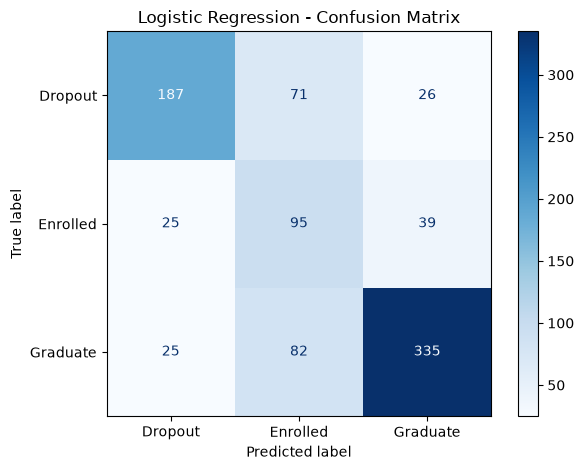

In [7]:

# 10. Predict the test set
y_pred_lr = best_lr.predict(X_test)

# 11. Calculate test accuracy
test_accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Test Accuracy:",
      round(test_accuracy_lr, 4))

# test macro F1 
from sklearn.metrics import f1_score
print("Logistic Regression Test Macro F1:",
      round(f1_score(y_test, y_pred_lr, average="macro"), 4))

# 12. Print precision, recall, and F1-score for each class
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=[0, 1, 2],
        target_names=["Dropout", "Enrolled", "Graduate"],
        digits=4,
        zero_division=0
    )
)

# 13. Plot the confusion matrix
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Dropout", "Enrolled", "Graduate"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [8]:
# 14. Compare the hyperparameter tuning results
cv_results_lr = pd.DataFrame(grid_search_lr.cv_results_)

tuning_results_lr = cv_results_lr[
    [
        "param_C",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score")

tuning_results_lr = tuning_results_lr.rename(
    columns={
        "param_C": "C",
        "mean_test_score": "Mean CV Macro F1",
        "std_test_score": "CV Standard Deviation",
        "rank_test_score": "Rank"
    }
)

print(tuning_results_lr.to_string(index=False))


     C  Mean CV Macro F1  CV Standard Deviation  Rank
  1.00          0.684854               0.010505     1
  0.10          0.684475               0.012796     2
100.00          0.679723               0.013555     3
 10.00          0.678466               0.013322     4
  0.01          0.664537               0.015422     5
